# Linked insights — CCTV images × scraped data
Seven insights. Each one combines the course data (CCTV images → YOLO counts, `cctv_info.csv`) with at least one scraped source.

| Source | Script | Used in |
|---|---|---|
| CCTV images (YOLO counts) | `p1`, `p2` | all |
| `cctv_info.csv` (camera location) | `p0` | all |
| BMA rain gauges | `s1` | 1–7 (dry/rain split), 3, 4 |
| Airport METAR | `s2` | 3 |
| Open-Meteo | `s3` | 3 |
| Sunrise/sunset | `s4` | 1, 2, 3, 7 |
| Thai holidays | `s5` | 1, 4, 5 |
| OpenStreetMap roads + places | `s6` | 2, 5, 6, 7 |
| BMA road flood sensors | `s8` | 4 |
| BMA flood-risk points | `s9` | 4 |

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})
D = '../data/clean/'
F = pd.read_csv(D + 'fact_images.csv', parse_dates=['ts'])
F['day'] = F.day_type.map({'วันธรรมดา': 'weekday', 'วันหยุด': 'weekend'})
cams = pd.read_csv('../data/cameras.csv')
osm = pd.read_csv(D + 'osm_camera_context.csv')
sun = pd.read_csv(D + 'sun_daily.csv')
hol = pd.read_csv(D + 'day_type.csv')
t = F.ts.dt.strftime('%H:%M')
F = F.merge(sun, left_on='date', right_on='date', how='left')
F['light'] = np.select([t < F.sunrise, t < F.sunset, t < F.civil_dusk], ['before sunrise', 'day', 'dusk'], 'night')
dry = F[F.rain_level == 'dry']
rng = np.random.default_rng(7)

def boot(df, col='cong_index', reps=1000):
    g = df.assign(l=np.log(df[col])).groupby('cam').l.agg(['sum', 'count'])
    s, n = g['sum'].to_numpy(), g['count'].to_numpy()
    if len(g) < 3:
        return pd.Series({'index': math.exp(s.sum() / n.sum()), 'lo': np.nan, 'hi': np.nan, 'images': int(n.sum()), 'cams': len(g)})
    k = rng.integers(0, len(g), size=(reps, len(g)))
    m = np.sort(s[k].sum(1) / n[k].sum(1))
    return pd.Series({'index': math.exp(s.sum() / n.sum()), 'lo': math.exp(m[int(.025 * reps)]), 'hi': math.exp(m[int(.975 * reps)]), 'images': int(n.sum()), 'cams': len(g)})

print(len(F), 'images ·', F.cam.nunique(), 'cameras · holidays in range:', hol.holiday.notna().sum())

60461 images · 100 cameras · holidays in range: 0


## Insight 1 — Weekdays have two peaks, weekends one at noon
Data: YOLO counts · `s5` holidays (day type) · `s1` rain (dry hours only) · `s4` daylight

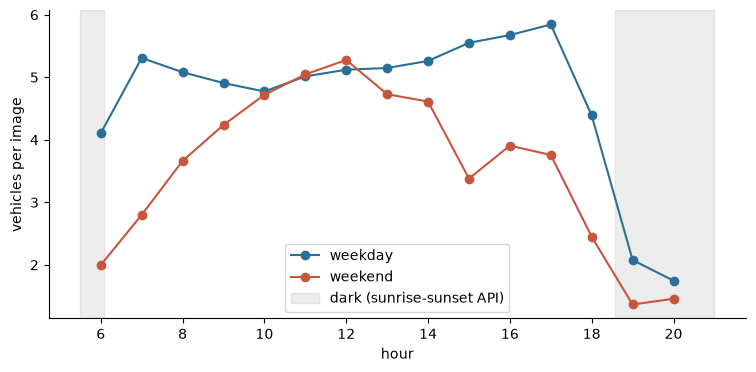

weekend vs weekday daily level: -0.248
weekday-to-weekday hourly correlation: 0.85–0.95


hour,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
day,,,,,,,,,,,,,,,
weekday,4.11,5.31,5.08,4.91,4.77,5.01,5.12,5.15,5.26,5.55,5.67,5.84,4.39,2.08,1.75
weekend,2.00,2.80,3.66,4.24,4.72,5.05,5.28,4.73,4.61,3.38,3.91,3.76,2.45,1.37,1.46


In [2]:
pat = dry.groupby(['hour', 'day']).vehicles.mean().unstack()
ax = pat.plot(marker='o', color={'weekday': '#2a6f97', 'weekend': '#c8553d'})
s0 = sun.iloc[0]
ax.axvspan(5.5, int(s0.sunrise[:2]) + int(s0.sunrise[3:]) / 60, color='grey', alpha=.15)
ax.axvspan(int(s0.sunset[:2]) + int(s0.sunset[3:]) / 60, 21, color='grey', alpha=.15, label='dark (sunrise-sunset API)')
ax.set_ylabel('vehicles per image'); ax.legend(); plt.show()
daily = dry.groupby(['day', 'date']).vehicles.mean()
print('weekend vs weekday daily level:', round(daily['weekend'].mean() / daily['weekday'].mean() - 1, 3))
prof = dry[dry.day == 'weekday'].groupby(['date', 'hour']).vehicles.mean().unstack()
corr = prof.T.corr().values[np.triu_indices(len(prof), 1)]
print('weekday-to-weekday hourly correlation: %.2f–%.2f' % (corr.min(), corr.max()))
pat.round(2).T

## Insight 2 — Evening is heavier than morning, most of all near rail stations and on smaller roads
Data: YOLO counts · `cctv_info` · `s6` OSM rail stations and road class · `s4` (both peaks are in daylight)

In [3]:
wd = dry[dry.day == 'weekday']
am = wd[wd.hour.isin([7, 8])].groupby('cam').vehicles.mean()
pm = wd[wd.hour.isin([16, 17])].groupby('cam').vehicles.mean()
X = osm.set_index('cam').join((am / pm).rename('am_pm'))
print('evening-heavy (>1.3x):', int((X.am_pm < 1 / 1.3).sum()), '· morning-heavy (>1.3x):', int((X.am_pm > 1.3).sum()))
peak = wd.groupby(['cam', 'hour']).vehicles.mean().unstack().idxmax(axis=1)
print('cameras by peak hour:', peak.value_counts().sort_index().to_dict())
print('peak hours are in daylight: 07:00 > sunrise', sun.sunrise.max(), '· 17:00 < sunset', sun.sunset.min())
X['near_rail'] = X.poi_rail_station_300m > 0
print(X.groupby('near_rail').am_pm.agg(['median', 'count']).round(2))
print('Spearman am/pm vs rail stations:', stats.spearmanr(X.poi_rail_station_300m, X.am_pm))
X.groupby('highway').am_pm.agg(['median', 'count']).round(2)

evening-heavy (>1.3x): 38 · morning-heavy (>1.3x): 11
cameras by peak hour: {6: 3, 7: 15, 8: 7, 9: 3, 10: 3, 11: 5, 12: 4, 13: 6, 14: 5, 15: 7, 16: 15, 17: 25, 18: 2}
peak hours are in daylight: 07:00 > sunrise 06:06 · 17:00 < sunset 18:30
           median  count
near_rail               
False        0.89     79
True         0.65     21
Spearman am/pm vs rail stations: SignificanceResult(statistic=np.float64(-0.23866083406235727), pvalue=np.float64(0.016790356016126433))


,median,count
highway,,
motorway,0.89,6
primary,0.89,55
secondary,0.82,32
tertiary,0.53,5
trunk,0.66,2


## Insight 3 — Weekday rain: cameras see 15–30% fewer vehicles, also in full daylight
Data: YOLO counts · `s1` rain per camera · `s4` daylight (separates rain from darkness) · `s2` METAR (rain confirmed at airports) · `s3` Open-Meteo (what a model-only approach would conclude)

In [4]:
Mm = F[F.baseline_matched == 1]
res = Mm.groupby(['day', 'rain_level']).apply(boot).round(3)
by_light = Mm[Mm.day == 'weekday'].groupby(['light', 'rain_level']).apply(boot).round(3)
display(res); display(by_light)

index     lo     hi   images   cams
day     rain_level                                     
weekday dry         0.944  0.931  0.956  41005.0  100.0
        heavy       0.679  0.632  0.743     82.0    9.0
        light       0.779  0.734  0.830   1646.0   93.0
weekend dry         0.981  0.967  0.996  15158.0  100.0
        heavy       0.884  0.780  1.023    532.0   67.0
        light       0.970  0.907  1.033    897.0   76.0

index     lo     hi   images   cams
light          rain_level                                     
before sunrise dry         0.657  0.609  0.715    291.0  100.0
day            dry         0.944  0.931  0.955  34323.0  100.0
               heavy       0.679  0.627  0.743     82.0    9.0
               light       0.854  0.798  0.918    764.0   90.0
dusk           dry         0.737  0.699  0.774    931.0  100.0
               light       0.498  0.424  0.578    120.0   51.0
night          dry         1.003  0.979  1.030   5460.0  100.0
               light       0.762  0.701  0.829    762.0   83.0

In [5]:
met = pd.read_csv(D + 'metar_30min.csv')
print('airport reports with rain/thunderstorm (RA, +RA, TSRA):')
print(met[met.rain_level >= 2][['station', 'valid', 'wxcodes']].to_string(index=False))

airport reports with rain/thunderstorm (RA, +RA, TSRA):
station            valid wxcodes
   VTBD 2026-08-28 18:00      RA
   VTBD 2026-08-29 15:00   +TSRA
   VTBS 2026-08-29 15:30   -TSRA
   VTBS 2026-08-29 16:00   -TSRA
   VTBD 2026-08-30 16:30      RA
   VTBS 2026-08-31 17:00     +RA
   VTBS 2026-08-31 17:30   -TSRA


In [6]:
om = pd.read_csv(D + 'openmeteo_hourly.csv')
om['date'] = om.time.str[:10]
om['hour'] = om.time.str[11:13].astype(int) - 1
om['cam'] = om.point.astype(int)
X = F.merge(om[['cam', 'date', 'hour', 'precipitation']], on=['cam', 'date', 'hour'], how='left')
X['om_level'] = np.select([X.precipitation < 0.5, X.precipitation < 5], ['dry', 'light'], 'heavy')
base = X[X.om_level == 'dry'].groupby(['cam', 'hour', 'day']).vehicles.agg(['median', 'size'])
X = X.join(base, on=['cam', 'hour', 'day'])
X = X[X['size'] >= 3].assign(om_index=lambda d: (d.vehicles + 1) / (d['median'] + 1))
print('rain/no-rain agreement station vs Open-Meteo:', round(((X.om_level != 'dry') == (X.rain_level != 'dry')).mean(), 2))
print('images flagged as rain — stations:', int((F.rain_level != 'dry').sum()), '· Open-Meteo:', int((X.om_level != 'dry').sum()))
X.groupby(['day', 'om_level']).apply(lambda d: boot(d, 'om_index')).round(3)

rain/no-rain agreement station vs Open-Meteo: 0.7
images flagged as rain — stations: 4298 · Open-Meteo: 16758


index     lo     hi   images   cams
day     om_level                                     
weekday dry       0.952  0.939  0.966  29747.0  100.0
        heavy     1.001  0.877  1.180    126.0   21.0
        light     0.927  0.898  0.957  12860.0  100.0
weekend dry       0.978  0.965  0.992  10423.0  100.0
        heavy     0.971  0.841  1.136    136.0   23.0
        light     1.020  0.978  1.069   3636.0  100.0

## Insight 4 — Weekend rain barely changes traffic; flood-prone spots are not worse
Data: YOLO counts · `s5` day type · `s1` rain · `s8` road flood sensors · `s9` flood-risk points with fix status

In [7]:
ff = pd.read_csv(D + 'fact_images_flood.csv')
ff['day'] = ff.day_type.map({'วันธรรมดา': 'weekday', 'วันหยุด': 'weekend'})
fl = pd.read_csv(D + 'bma_road_flood_hourly.csv')
print('images with a road flood sensor within 1 km:', int(ff.flood_cm.notna().sum()), '· with water on the road:', int(ff.road_flooded.sum()))
print('sensors with water this week:', fl[fl.flood_cm > 0].sensor.unique())
ff[(ff.baseline_matched == 1) & (ff.day == 'weekend')].groupby(['flood_group', 'rain_level']).apply(boot).round(3)

images with a road flood sensor within 1 km: 44751 · with water on the road: 0
sensors with water this week: <StringArray>
['FL.RTW.02']
Length: 1, dtype: str


index     lo     hi  images  cams
flood_group     rain_level                                   
near_fixed_only dry         0.971  0.949  0.996  4360.0  28.0
                heavy       0.887  0.715  1.126   138.0  20.0
                light       1.020  0.935  1.114   270.0  22.0
near_unfixed    dry         0.979  0.956  1.008  3187.0  21.0
                heavy       0.743  0.617  0.897   118.0  15.0
                light       1.038  0.908  1.216   198.0  15.0
not_near        dry         0.987  0.964  1.011  7611.0  51.0
                heavy       0.951  0.768  1.166   276.0  32.0
                light       0.911  0.833  1.010   429.0  39.0

## Insight 5 — Weekend vs weekday depends on the place
Data: YOLO counts · `s5` day type · `s6` OSM places within 300 m

In [8]:
mid = dry[dry.hour.between(9, 14)].groupby(['cam', 'day']).vehicles.mean().unstack()
mid['weekend_ratio'] = mid.weekend / mid.weekday
X = cams.set_index('cam')[['name_th']].join(mid).join(osm.set_index('cam'))
print('median weekend/weekday:', round(X.weekend_ratio.median(), 2))
for c in ['poi_mall_300m', 'poi_market_300m', 'poi_office_300m', 'poi_government_300m', 'poi_rail_station_300m', 'poi_food_300m']:
    r = stats.spearmanr(X[c], X.weekend_ratio)
    print('%-24s rho %+.2f  p %.2f' % (c, r.statistic, r.pvalue))
cols = ['name_th', 'weekday', 'weekend', 'weekend_ratio', 'road_name', 'poi_mall_300m', 'poi_market_300m', 'poi_office_300m', 'poi_government_300m', 'poi_rail_station_300m']
pd.concat([X.sort_values('weekend_ratio', ascending=False).head(5), X.sort_values('weekend_ratio').head(5)])[cols].round(2)

median weekend/weekday: 0.98
poi_mall_300m            rho +0.03  p 0.75
poi_market_300m          rho -0.00  p 0.98
poi_office_300m          rho -0.03  p 0.79
poi_government_300m      rho +0.01  p 0.94
poi_rail_station_300m    rho +0.15  p 0.14
poi_food_300m            rho +0.06  p 0.57


,name_th,weekday,weekend,weekend_ratio,road_name,poi_mall_300m,poi_market_300m,poi_office_300m,poi_government_300m,poi_rail_station_300m
cam,,,,,,,,,,
176,สะพานลอยหน้าสวนจตุจักร-ถนนพ,1.95,3.12,1.60,ถนนพหลโยธิน,1,0,0,0,2
301,แยกอู่ทองนอก,4.27,5.70,1.33,ถนนนครราชสีมา,0,0,1,3,0
88,แยกจันทน์-สาธุประดิษฐ์-ด้านถ,2.20,2.83,1.29,ถนนจันทน์,0,2,1,0,0
1195,แยกบุคคโล(ถนนมไหสวรรค์ขาเข้,7.93,9.86,1.24,ถนนพระรามที่ 3,0,0,2,0,0
125,แยกรัชดา-ลาดพร้าว-ด้านถนนลาด,3.22,3.95,1.23,ถนนรัชดาภิเษก,0,1,1,0,2
206,สะพานลอยใกล้ซอยนราธิวาสราช,1.38,0.47,0.34,ถนนนราธิวาสราชนครินทร์,0,0,1,0,0
277,ทางแยกอ.ชัยสมรภูมิ,14.45,9.22,0.64,วงเวียนอนุสาวรีย์ชัยสมรภูมิ,2,2,1,0,1
939,TF-KP-04-แยกมหาดไทย,1.61,1.08,0.67,ถนนรามคำแหง,0,0,1,1,0
233,ตรงข้ามพระตำหนักจิตรลดารโห,1.49,1.02,0.68,ถนนพระรามที่ 5,0,0,0,1,0


## Insight 6 — Busiest areas follow road class, and Friday evening is the busiest time
Data: YOLO counts · `s1` station district · `s6` OSM road class · `s4` daylight

In [9]:
st = pd.read_csv(D + 'bma_rain_stations.csv')
cams['district'] = [st.district.iloc[((st.lat - r.lat) ** 2 + ((st.lon - r.lon) * 0.97) ** 2).idxmin()] for r in cams.itertuples()]
X = cams.set_index('cam').join(osm.set_index('cam')).join(dry.groupby('cam').vehicles.mean().rename('veh'))
print(X.groupby('highway').veh.agg(['median', 'count']).round(2).sort_values('median', ascending=False))
print('Kruskal-Wallis across road classes p =', round(stats.kruskal(*[g.veh for _, g in X.groupby('highway') if len(g) >= 5]).pvalue, 4))
area = X.groupby('district').agg(cams=('veh', 'size'), vehicles=('veh', 'mean'), primary_share=('highway', lambda s: (s.isin(['motorway', 'trunk', 'primary'])).mean()))
display(area[area.cams >= 4].sort_values('vehicles', ascending=False).round(2))
dow = dry.assign(dow=dry.ts.dt.day_name())
dow[(dow.hour.between(16, 18)) & (dow.light == 'day')].groupby('dow').vehicles.mean().round(2)

           median  count
highway                 
motorway     6.22      6
primary      4.23     55
secondary    3.77     32
trunk        3.31      2
tertiary     2.49      5
Kruskal-Wallis across road classes p = 0.4643


,cams,vehicles,primary_share
district,,,
ราชเทวี,5,6.77,0.80
ธนบุรี,5,5.78,1.00
ป้อมปราบฯ,7,5.23,0.14
บางรัก,5,5.19,0.60
ยานนาวา,4,5.11,1.00
พญาไท,5,4.98,1.00
ห้วยขวาง,9,4.60,1.00
ปทุมวัน,5,4.04,0.60
จตุจักร,13,3.96,1.00


dow
Friday       6.35
Monday       4.85
Saturday     3.83
Sunday       3.48
Thursday     5.58
Tuesday      5.51
Wednesday    5.77
Name: vehicles, dtype: float64

## Insight 7 — Vehicle mix depends on road class and surroundings; trucks avoid weekday rush hours
Data: YOLO class counts · `s6` OSM road class, food places and offices · `s4` daylight · `s5` day type

In [10]:
mix = F.groupby('cam')[['car', 'motorcycle', 'bus', 'truck', 'vehicles']].sum()
pct = mix[['motorcycle', 'bus', 'truck']].div(mix.vehicles, axis=0).mul(100).add_suffix('_%')
X = cams.set_index('cam')[['name_th']].join(pct).join(osm.set_index('cam'))
print(X.groupby('highway')[['bus_%', 'truck_%', 'motorcycle_%']].median().round(1))
for a, b in [('motorcycle_%', 'poi_food_300m'), ('motorcycle_%', 'poi_office_300m')]:
    r = stats.spearmanr(X[a], X[b]); print('%s vs %s: rho %+.2f p %.3f' % (a, b, r.statistic, r.pvalue))
display(X.sort_values('motorcycle_%', ascending=False).head(4)[['name_th', 'motorcycle_%', 'road_name', 'poi_food_300m', 'poi_office_300m']].round(1))
day_only = dry[dry.light == 'day'].groupby(['day', 'hour'])[['truck', 'vehicles']].sum()
(day_only.truck / day_only.vehicles * 100).unstack(0).round(1).T

           bus_%  truck_%  motorcycle_%
highway                                
motorway     8.8     14.2           1.3
primary     12.0      8.2           0.5
secondary    6.7      7.7           3.7
tertiary     4.6      5.0           1.8
trunk        5.1     11.9           0.2
motorcycle_% vs poi_food_300m: rho +0.22 p 0.025
motorcycle_% vs poi_office_300m: rho +0.14 p 0.154


,name_th,motorcycle_%,road_name,poi_food_300m,poi_office_300m
cam,,,,,
603,BR-05-01-แยกสีลม-นราธิวาส,35.8,ถนนสีลม,72,26
500,ทางแยกมิตรสัมพันธ์,26.4,ถนนเพชรบุรี,36,0
371,แยกเทเวศน์,23.2,ถนนกรุงเกษม,41,9
118,แยกรัชดา-สุทธิสาร-ด้านถนนสุท,19.3,ถนนรัชดาภิเษก,14,1


hour,6,7,8,9,10,11,12,13,14,15,16,17,18
day,,,,,,,,,,,,,
weekday,7.9,7.9,8.4,10.7,10.4,10.4,9.9,10.4,10.5,9.1,8.3,7.6,6.2
weekend,11.0,10.5,10.3,10.2,9.7,10.1,8.7,8.5,9.1,8.1,7.5,8.3,5.6


## Notes
- Class labels come from a COCO-trained model: *truck* includes pickups; check top cameras by eye.
- 7 days of data; rain only in afternoons/evenings; correlations, not causes.
- Manual count of 200 images (`p5_label_sample.py`) is still needed to confirm Insight 3.